# Chem: lab notebook

**Question.** What does a chemistry of more than one resource do to EvoCA? The first instance is **food/waste**: metabolism turns food into waste, cells must excrete waste into an environmental waste field, and waste kills at a threshold. Two reasons to build it now:

- **A refractory medium.** The standard model has no refractory mechanism, so it makes no spiral (scroll) waves (Reaction-diffusion, RXD-Q6). An inhibitor/waste field is the only acceptable path (N, 2026-10-23).
- **Selection at abundance.** Waste installs a density-dependent cost that stays selective where the food axis goes slack (checkpoint LB6, section B).

Longer term this workstream carries the autocatalytic reaction-network chemistry (Farmer-Kauffman-Packard 1986; milestone 3).

Links: design [`Docs/plan-chem.md`](../../Docs/plan-chem.md) (sections 1-2 storage and the f mapping; section 7 food/waste) · checkpoint LB6 / E1-E3 in [`Docs/checkpoint 3 July 2026.md`](../../Docs/checkpoint%203%20July%202026.md) · tests `tests/test_chem_parity.py`, `tests/test_chem_waste.py`.

**Eating rule.** All runs use the standard model (capped mouthful, `food_cap=1`).

Every simulation here is an **example run** (one seed, small N), not a campaign result.

## Setup

In [1]:
import sys, time, json, os, hashlib
from pathlib import Path
_t0 = time.time()
p = Path.cwd().resolve()
while not (p / 'C' / 'evoca.h').exists():
    if p.parent == p: raise FileNotFoundError('EvoCA repo root not found')
    p = p.parent
ROOT = p
sys.path.insert(0, str(ROOT / 'python')); sys.path.insert(0, str(ROOT / 'tests'))
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from evoca_py import EvoCA
from evoca_nb import make_sim, export_recipe_once
from evoca_gallery import Gallery, Entry
from colormodes import COLOR_MODES

WS = 'Chem'
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)

def fingerprint(s):
    h = hashlib.sha1()
    for a in (s.get_F(), s.get_f(), s.get_v(), s.get_alive(), s.get_lut_hashes()):
        h.update(np.ascontiguousarray(a).tobytes())
    return h.hexdigest()[:12]

def osc(a, every=10):
    # Second half of an alive-fraction series: range, std, dominant FFT period (steps).
    x = np.asarray(a)[len(a) // 2:]; f = np.abs(np.fft.rfft(x - x.mean())); k = f[1:].argmax() + 1
    return dict(lo=round(x.min(), 3), hi=round(x.max(), 3), std=round(x.std(), 3), period=round(len(x) * every / k))

*Snapshot of `ISSUES.md` as of the last execution of this notebook; `ISSUES.md` is the source of truth.*

In [2]:
display(Markdown((ROOT / 'Research' / WS / 'ISSUES.md').read_text()))

# Chem: issues and directions
_Updated 2026-10-23_

## Decisions needed (N)
- **CHEM-D2**: Should environmental waste saturate? — Currently `W` is unbounded and mass-conserving: excretion stops at `W >= 1`, but deaths still return waste, so where the sink is slower than production (`waste_sink` < tax x density) `W` piles up to 5-12, cells can never excrete, and waste acts as uniform aging (lifespan ~ 1/tax). Option: cap `W` at 1 with the excess discarded and booked as an overflow sink, the counterpart of the food `F <= 1` regeneration cap (N's "parallel to food" principle). Recommendation: keep unbounded for now (conserving, and the balance regime is where structure appears); revisit if the aging regime matters.

## Decided
- **CHEM-D1** (2026-10-23): merged to `main` (`1a41c5d`, fast-forward) after a local review and the cloud `/code-review ultra`; findings fixed (CHEM-F1), shared `diffuse()` parked (CHEM-P1).
- **CHEM-D3** (N, 2026-10-23): yes to wgenes, after a short look at global chem (CHEM-N5). Hereditary local chemistries are the longer-term goal; wgenes are the first step: the chemistry stays global and one exchange becomes heritable. Design (to confirm in the dev plan): wgenes use the egene representation (ternary D4 patterns, max signed match `wscore` clamped at 0); excretion `d = disp * (b + (1-b) * wscore/25) * a * (1-E)`, with a floor `b` so that `b = 1` reproduces today's uniform excretion bit-for-bit (the first parity test); `tax_per_wgene` and `mu_wgene` by symmetry with eating; wgenes enter the genome hash and the neutral shadow mutates them (see the egene shadow mismatch). Built as per-compound exchange genes (egenes = uptake of compound 0, wgenes = excretion of compound 1), separate sets from egenes at first. Motivation: eating and excreting then demand different local CA patterns, which can select for temporal alternation, a visible dynamics change driven by heritable function (the activity-to-visual link, `Docs/activity-thoughts.md`).

## Open questions
- **CHEM-Q1**: Does food/waste give the standard (capped) model a refractory medium with propagating waves or spirals? — First look (notebook, 2026-10-23, N=256, one seed): at the legacy-spiral parameter point under the cap, waste produces a sustained oscillating patchy regime near the balance `waste_sink ~ tax x density` (`waste_sink` 0.014-0.015), absent without waste and on either side of the balance. Whether the patches propagate as waves, and whether any rotate, is not yet established.
- **CHEM-Q2**: Does waste keep selection alive at abundance (checkpoint section B / LB6 hypothesis)? — Untested. Needs evolution metrics (dyn_excess, A_new) at high `food_inc` with waste on and off.
- **CHEM-Q3**: In the sink-limited (aging) regime, is there selection for cheaper genomes (lower evolvable tax terms), since lifespan is ~ 1/tax?

## Next directions
- **CHEM-N1**: Wave survey around the balance — campaign (torque): N=512, `waste_sink` x `waste_disp` x `wdiff` x `food_inc`, films, and the spiral detector shared with RXD-N6 (phase singularities of the local food/waste oscillation).
- **CHEM-N2**: Selection at abundance (section B high flank) — campaign: high `food_inc`, waste on/off, dyn_excess / A_new, 3+ seeds.
- **CHEM-N3**: wgenes (evolvable excretion) by symmetry with eating — dev, decided (CHEM-D3); starts after CHEM-N5.
- **CHEM-N5**: Robustness of the balance regime (`waste_sink ~ tax x density`): seeds, N=256/512, a `waste_sink` x `food_inc` grid; the global-chem baseline wgenes will be compared against — short campaign, before CHEM-N3.
- **CHEM-N4**: Milestone 3, the reaction network (FKP-style autocatalysis) and egene -> compound-profile eating — dev, `Docs/plan-chem.md`.

## Fixed
- **CHEM-F1** (2026-10-23): review fixes, `Docs/plan-chem.md` §8. Setters and stamps that kill a cell, replace its occupant or rewrite its store (`stamp_patch`, `set_f_all`, `set_alive*`, `set_w`) now keep the waste-mass balance. Waste can no longer carry energy (an energy-1 product made the tax free). `set_n_chem`, a refused `init` and the controls Restart keep `params()`/recipes in agreement with C (Restart had silently dropped the food/waste chemistry). Colormode 6 shows waste with metabolism off. NaN scan-row cells are dropped. Per-compound `get_chem_env`/`get_chem_priv` were added. Ordinary food/waste runs are unchanged: the notebook outputs are identical.

## Parked
- **CHEM-P1**: One shared `diffuse(field, tmp, d)` for the three copies of the 3x3 periodic box blur (food full and partial passes, compound fields). A separate refactor; it must keep the food goldens bit-exact.


## The chemistry (milestone 2, 2026-10-23)

**The general mechanism (C).** Every compound has an environment field and an exchange with the agents. Compound 0 is the energy compound, food; its field is `F` with source `food_inc`, diffusion `gdiff`, and intake by eating. A compound c >= 1 has:

- its own field, with a uniform source, a uniform sink and its own diffusion;
- excretion from the cell into its own site, `d = disp * a * max(0, 1 - E)`;
- a toxic private amount;
- an energy weight of 0 or 1.

The one reaction so far is **metabolism**: the tax converts food into a product compound. With no product it is simply dissipated, which is the single-food model. On death, a cell's compounds return to its site.

**Food/waste is one configuration of it** (`EvoCA.init(n_chem=2, wdiff, waste_sink, waste_disp)`):

| waste | value |
|---|---|
| made by | the tax (food -> waste, 1:1) |
| energy | 0 (does not count toward `f`, reproduction or headroom) |
| kills at | private amount 1 |
| excretion | `waste_disp * w * (1 - W)` into the cell's site |
| environment | no source, uniform sink `waste_sink`, diffusion `wdiff`: the counterparts of `food_inc` and `gdiff` |
| on death | food and waste return to the site (toxic death); waste returns (tax death, eviction) |

**Step order:** CA -> food source and diffusion -> waste sink and diffusion -> tax/metabolism (tax death) -> excretion and toxicity (toxic death) -> eating -> reproduction (every compound splits 50/50).

Full table and tests: `Docs/plan-chem.md` section 7.

**A one-step check.** All cells alive with f = 0.5 and no eating; tax 0.03, `waste_disp` 0.25. After one step each cell has f = 0.47; its new waste 0.03 is split 0.0225 kept and 0.0075 excreted into W.

In [3]:
s = make_sim(16, food_inc=0.0, m_scale=0.0, gdiff=0.0, tax=0.03, n_chem=2, waste_disp=0.25)
s.state(lut='gol', egenome='uniform', egenome_value=3); s.set_F_all(0.0); s.set_alive_all(); s.set_f_all(0.5)
s.step()
print('f %.4f  private waste w %.4f  env waste W %.4f  (expect 0.4700, 0.0225, 0.0075)' % (s.get_f().mean(), s.get_w().mean(), s.get_W().mean()))
print('waste params (inc, sink, diff, disp, tox):', s.get_chem_params(1), '| metabolic product:', s.get_metab_product(), '| waste energy weight:', s.get_chem_energy(1))
s.free()

f 0.4700  private waste w 0.0225  env waste W 0.0075  (expect 0.4700, 0.0225, 0.0075)
waste params (inc, sink, diff, disp, tox): (0.0, 0.0, 0.0, 0.25, 1.0) | metabolic product: 1 | waste energy weight: 0.0


**The single-food model is a special case, exactly.** Two parity checks, both bit for bit:

- **Milestone-1 golden.** `N_chem=1` reproduces the pre-chem single-food golden (`tests/chem_parity.py`).
- **The general path.** `N_chem=2` with every compound inert (no metabolism, no exchange, no environment dynamics) reproduces the `N_chem=1` run. It runs the general multi-compound split, excretion and eviction code, so this checks that code, not just the old path.

In [4]:
import chem_parity as cp                      # tests/chem_parity.py
ok, lines = cp.compare(cp.load_golden(), cp.run_and_capture(EvoCA()))
print('milestone-1 golden (N_chem=1):', 'PASS' if ok else 'FAIL'); print('\n'.join(lines))
# (that golden was recorded under the legacy rule, food_cap=0: it gates the storage code path, not the eating rule)

def evolving(N=48, seed=1, n_chem_after_init=None, **kw):
    rng = np.random.default_rng(seed)
    p = dict(food_inc=0.015, m_scale=3.0, gdiff=0.08, tax=0.02, mu_lut=0.01, mu_egene=0.03); p.update(kw)
    s = make_sim(N, **p)
    if n_chem_after_init: s._lib.evoca_set_n_chem(n_chem_after_init)   # C level: compound 1 exists but is inert
    s.set_seed(seed); s.state(lut='gol', egenome='uniform', egenome_value=3)
    s.set_v(rng.integers(0, 2, (N, N), dtype=np.uint8)); s.set_f_all(0.5); s.set_F_all(1.0); s.set_alive_halfplane(0)
    return s

fp = {}
for n in (None, 2):
    s = evolving(n_chem_after_init=n)
    for _ in range(300): s.step()
    fp[n or 1] = fingerprint(s); s.free()
print('standard rule, 300 steps: N_chem=1 %s | inert N_chem=2 %s ->' % (fp[1], fp[2]), 'PASS' if fp[1] == fp[2] else 'FAIL')

milestone-1 golden (N_chem=1): PASS
  f         OK       (identical, 9216 values)
  F         OK       (identical, 9216 values)
  alive     OK       (identical, 9216 values)
  lut_hash  OK       (identical, 9216 values)
standard rule, 300 steps: N_chem=1 14f50abea4e7 | inert N_chem=2 14f50abea4e7 -> PASS


**Conservation.** In an evolving food/waste run (N=48, 300 steps), waste mass is conserved: each step, `d(sum W + sum w)` equals waste made (metabolism) minus waste removed (sink). That covers eviction, tax and toxic deaths, the split and diffusion. Energy obeys the same identity as in the single-food model: `source = d(storage) + dissipation`.

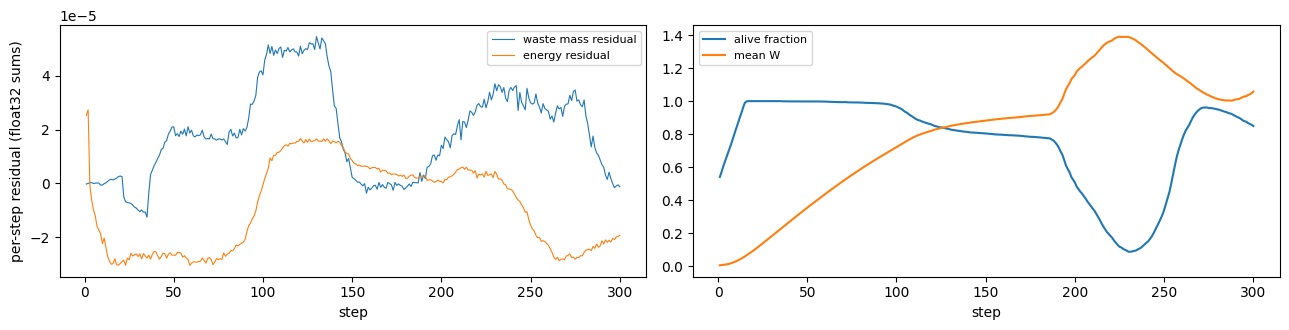

max |waste residual| 5.5e-05, max |energy residual| 3.1e-05, toxic deaths 2082


In [5]:
s = evolving(n_chem=2, wdiff=0.3, waste_sink=0.01, waste_disp=0.2)
mass = lambda: s.get_W().astype(np.float64).sum() + s.get_w().astype(np.float64).sum()
d0 = s.get_dissipation(); e_prev = d0['storage_env'] + d0['storage_priv']; m_prev = mass(); fl_prev = s.get_chem_flux(1)
rows = []
for t in range(300):
    s.step(); d = s.get_dissipation(); e = d['storage_env'] + d['storage_priv']; m = mass(); fl = s.get_chem_flux(1)
    rows.append(dict(t=t + 1, alive=s.get_alive().mean(), W=s.get_W().mean(), tox_deaths=s.get_tox_deaths_last(),
                     waste_residual=(m - m_prev) - ((fl[0] - fl_prev[0]) - (fl[1] - fl_prev[1])),
                     energy_residual=d['source_step'] - (e - e_prev + d['diss_step'])))
    e_prev, m_prev, fl_prev = e, m, fl
s.free()
R = pd.DataFrame(rows).set_index('t')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].plot(R.waste_residual, lw=0.8, label='waste mass residual'); ax[0].plot(R.energy_residual, lw=0.8, label='energy residual')
ax[0].set(xlabel='step', ylabel='per-step residual (float32 sums)'); ax[0].legend(fontsize=8)
ax[1].plot(R.alive, label='alive fraction'); ax[1].plot(R.W, label='mean W'); ax[1].set(xlabel='step'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('max |waste residual| %.1e, max |energy residual| %.1e, toxic deaths %d' % (R.waste_residual.abs().max(), R.energy_residual.abs().max(), R.tox_deaths.sum()))

## First look: a waste-limited medium at the legacy-spiral point (2026-10-23)

**Question.** Under the standard rule, the parameter point where the legacy rule made spirals (Resource-driving R1 row 208: `m_scale` 3.5, `food_inc` 0.016, `tax` 0.035, `gdiff` 0.08) is a uniform grazing texture (Reaction-diffusion notebook). Does adding waste change that?

**What was done (example runs, N=256, seed 0, 3000 steps).** That point with the cap, without waste and with food/waste at `waste_disp` 0.5 and `wdiff` 0.08 (= `gdiff`), sweeping `waste_sink`. Waste is made at the tax rate per live cell, so the environment can remove it all only if `waste_sink` exceeds about tax x density (0.035 x ~0.37 = 0.013). Frames are colormode 6: green = food, red = waste, blue = live cells (so live cells on food read cyan, live cells in waste read magenta).

In [6]:
# ── section setup: food/waste at the legacy-spiral point ─────────────
REC_SPIRAL = '2026-10-15_R1cfg208_intermediate_fi0p016.evoca'          # Resource-driving; final metaparams
mp = json.load(open(ROOT / 'Research' / 'Resource-driving' / 'Runs' / REC_SPIRAL))['metaparams_final']
FW = {**{k: v for k, v in mp.items() if k != 'food_cap'}, 'food_cap': 1, 'n_chem': 2, 'wdiff': 0.08, 'waste_disp': 0.5, 'waste_sink': 0.015}
s = make_sim(256, **FW)
s.state(lut='gol', egenome='uniform', egenome_value=3, alive='halfplane', F_init=1.0, f_init=0.5)
REC_FW = Path(export_recipe_once(s, 'chem_fw_spiralpoint', workstream=WS, colormode=6)).name; s.free()
SINKS = (0.005, 0.010, 0.013, 0.014, 0.015, 0.016, 0.020)
FW_SINK = Gallery('chem_fw_sink', [Entry(recipe=REC_SPIRAL, params='final', label='no_waste', overrides={'food_cap': 1},
                                         title='standard model, no waste', meta=dict(waste_sink=None))] +
                  [Entry(recipe=REC_FW, label=f'sink{k}', overrides={'waste_sink': k}, title=f'food/waste, waste_sink {k}',
                         meta=dict(waste_sink=k)) for k in SINKS],
                  description='legacy-spiral point under the cap: no waste, and food/waste swept over waste_sink',
                  workstream=WS, owner='First look')
FW_SINK.save()
FW_RUN = dict(N=256, n_steps=3000, every=10, snaps=(3000,), cms=(6,), metrics='alive')
FW_SINK

,label,title,source,params,overrides,waste_sink,food_inc,m_scale,gdiff,tax,mu_lut,mu_egene,restricted_mu,food_cap,n_chem,wdiff,waste_disp
0,no_waste,"standard model, no waste",2026-10-15_R1cfg208_intermediate_fi0p016.evoca,final,food_cap=1,0.000,0.016,3.5,0.08,0.035,0.03,0.003,1,1,1,0.00,0.0
1,sink0.005,"food/waste, waste_sink 0.005",2026-10-23_chem_fw_spiralpoint.evoca,NaN,waste_sink=0.005,0.005,0.016,3.5,0.08,0.035,0.03,0.003,1,1,2,0.08,0.5
2,sink0.01,"food/waste, waste_sink 0.01",2026-10-23_chem_fw_spiralpoint.evoca,NaN,waste_sink=0.01,0.010,0.016,3.5,0.08,0.035,0.03,0.003,1,1,2,0.08,0.5
3,sink0.013,"food/waste, waste_sink 0.013",2026-10-23_chem_fw_spiralpoint.evoca,NaN,waste_sink=0.013,0.013,0.016,3.5,0.08,0.035,0.03,0.003,1,1,2,0.08,0.5
4,sink0.014,"food/waste, waste_sink 0.014",2026-10-23_chem_fw_spiralpoint.evoca,NaN,waste_sink=0.014,0.014,0.016,3.5,0.08,0.035,0.03,0.003,1,1,2,0.08,0.5
5,sink0.015,"food/waste, waste_sink 0.015",2026-10-23_chem_fw_spiralpoint.evoca,NaN,waste_sink=0.015,0.015,0.016,3.5,0.08,0.035,0.03,0.003,1,1,2,0.08,0.5
6,sink0.016,"food/waste, waste_sink 0.016",2026-10-23_chem_fw_spiralpoint.evoca,NaN,waste_sink=0.016,0.016,0.016,3.5,0.08,0.035,0.03,0.003,1,1,2,0.08,0.5
7,sink0.02,"food/waste, waste_sink 0.02",2026-10-23_chem_fw_spiralpoint.evoca,NaN,waste_sink=0.02,0.020,0.016,3.5,0.08,0.035,0.03,0.003,1,1,2,0.08,0.5


chem_fw_sink: running 8 of 8 entries (0 cached), 8 worker(s)


,entry,waste_sink,alive_mean,W_mean,lo,hi,std,period
0,[0] no_waste,NaN,0.381,0.00,0.371,0.388,0.003,1500
1,[1] sink0.005,0.005,0.332,18.98,0.307,0.356,0.010,75
2,[2] sink0.01,0.010,0.333,9.04,0.302,0.370,0.011,79
3,[3] sink0.013,0.013,0.330,2.87,0.307,0.355,0.009,79
4,[4] sink0.014,0.014,0.324,0.95,0.283,0.364,0.016,136
5,[5] sink0.015,0.015,0.352,0.71,0.300,0.402,0.020,115
6,[6] sink0.016,0.016,0.379,0.54,0.366,0.388,0.004,1500
7,[7] sink0.02,0.020,0.381,0.20,0.371,0.388,0.003,1500


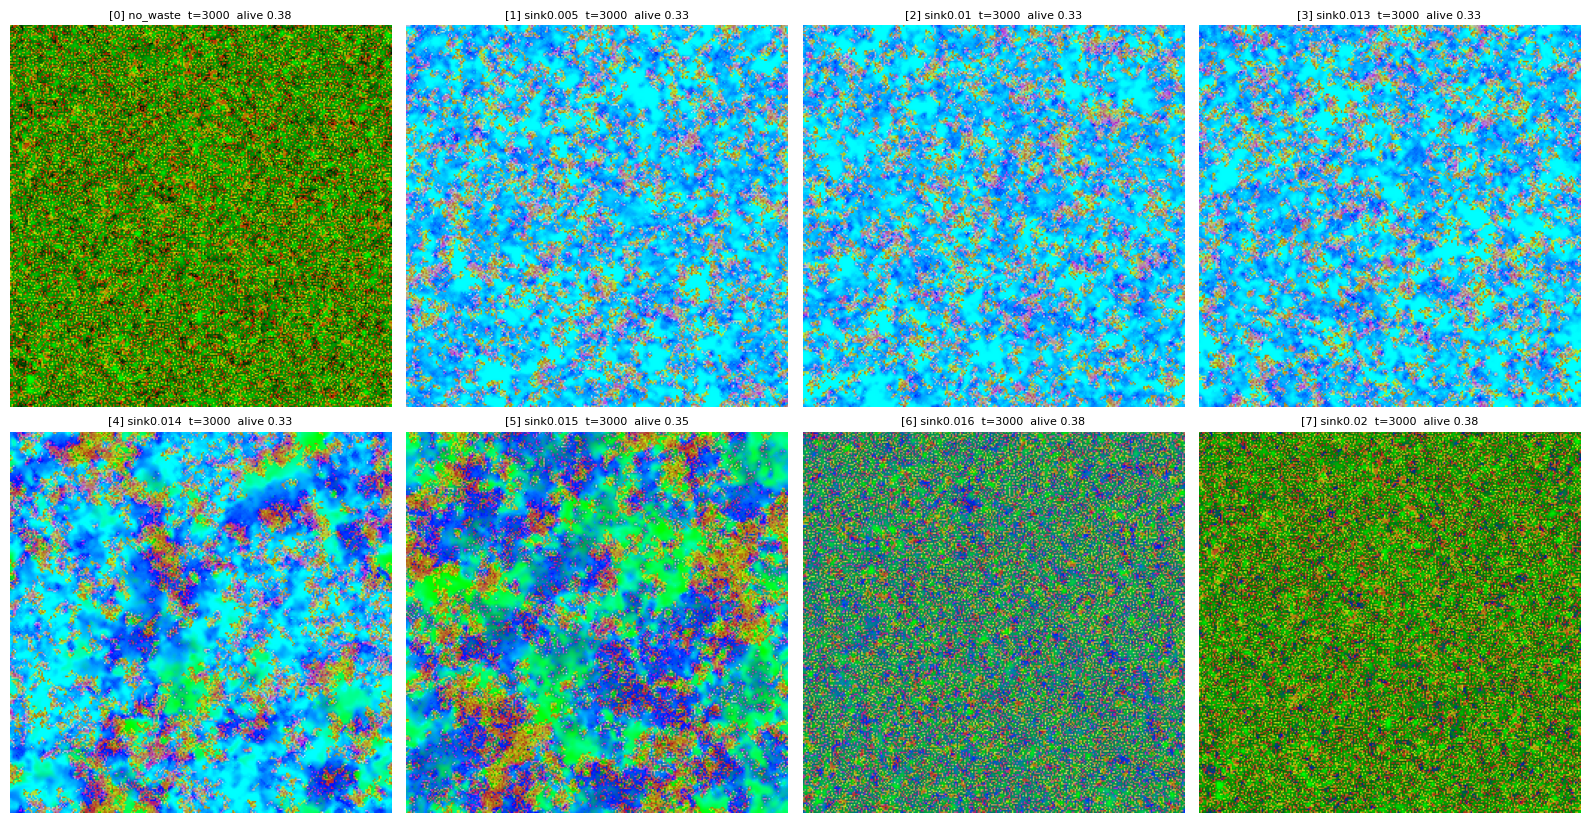

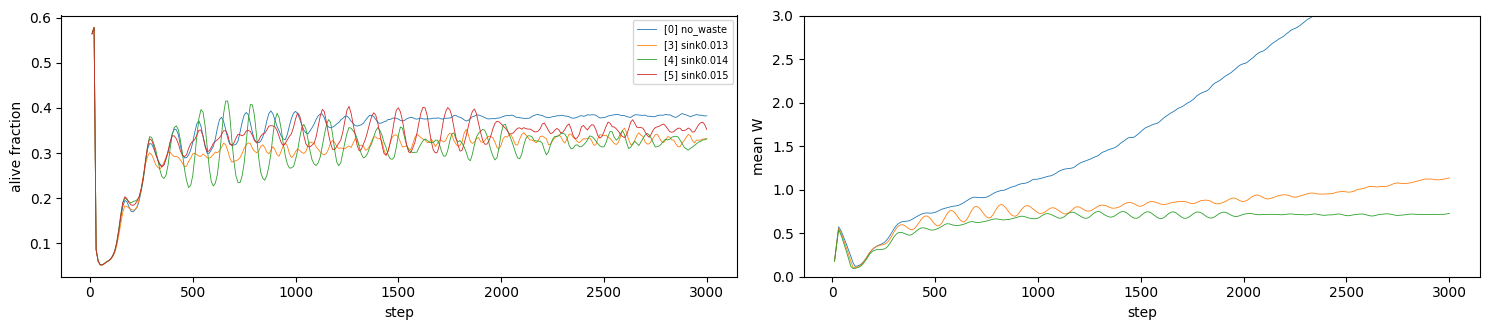

In [7]:
R = FW_SINK.run(**FW_RUN)
rows = []
for i, e in enumerate(FW_SINK):
    ts = R[i].ts
    rows.append(dict(entry=R.tag(i), waste_sink=e.meta['waste_sink'], alive_mean=round(ts.alive_density.iloc[len(ts)//2:].mean(), 3),
                     W_mean=round(ts.W_mean.iloc[len(ts)//2:].mean(), 2) if 'W_mean' in ts else 0.0, **osc(ts.alive_density)))
display(pd.DataFrame(rows))
fig, axs = plt.subplots(2, 4, figsize=(16, 8.4))
for k, ax in enumerate(axs.ravel()):
    ax.imshow(R[k].shots[3000][6]); ax.axis('off')
    ax.set_title(f"{R.tag(k)}  t=3000  alive {R[k].ts.alive_density.iloc[-1]:.2f}", fontsize=8)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(15, 3.4))
for k in (0, 3, 4, 5):
    ts = R[k].ts; ax[0].plot(ts.index, ts.alive_density, lw=0.6, label=R.tag(k))
    if 'W_mean' in ts: ax[1].plot(ts.index, ts.W_mean, lw=0.6, label=R.tag(k))
ax[0].set(xlabel='step', ylabel='alive fraction'); ax[1].set(xlabel='step', ylabel='mean W', ylim=(0, 3)); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Do the patches move?** The `waste_sink` 0.015 run, frames every 20 steps from t=2800 (colormode 6).

chem_fw_sink: running 1 of 1 entries (0 cached), 1 worker(s)


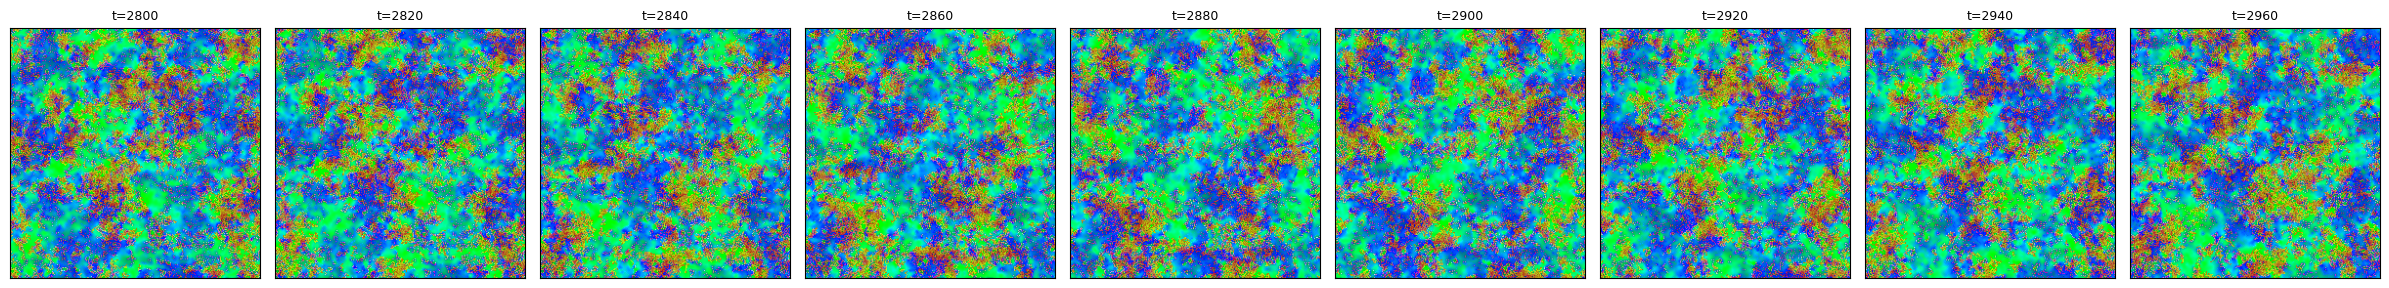

In [8]:
FILM = dict(N=256, n_steps=2960, every=20, snaps=tuple(range(2800, 2961, 20)), cms=(6,), metrics='alive')
F = FW_SINK[['sink0.015']].run(**FILM)
fig, axs = plt.subplots(1, len(FILM['snaps']), figsize=(24, 3.2))
for ax, t in zip(axs, FILM['snaps']):
    ax.imshow(F[0].shots[t][6]); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f't={t}', fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# Interactive (commented so that Run All does not open an SDL window); colormode 6 = food-waste, 7 = env-waste
# (like env-food, 1: dead cells show the env field, alive cells red 180 + their private store;
# switch modes with the color menu or the C key).
# FW_SINK.show('sink0.015', N=256)          # the oscillating patchy regime
# FW_SINK.show('sink0.015', N=512)        # more room for patches

**Observations (example runs, N=256, seed 0, not campaign results).**

- **Three regimes, set by the waste balance.**
  - *Sink above production* (`waste_sink` >= 0.016, against production ~ tax x density ~ 0.013): waste stays low (mean W 0.2-0.5) and the lattice is the same uniform grazing texture as without waste (alive 0.38, std 0.003-0.004).
  - *Sink below production* (<= 0.013): W piles up far above 1 (mean 3-19). Excretion stops but deaths keep returning waste, so every cell lives ~1/tax steps until poisoned. Waste then acts as uniform **aging**: a fine-grained texture, alive 0.33.
  - *Balance* (0.014-0.015): **lattice-scale structure** that the standard model does not have without waste.
- **What the balance regime looks like.** In colormode 6 (food-waste) the lattice divides into large patches of three kinds: clean food ground with no cells (green), colonies (speckled red-orange-yellow, cells with private food; purple where they carry waste), and waste-loaded ground (blue; cyan where food has regrown under the waste). That is the excitable / excited / refractory triple of an excitable medium: food that can be colonized, a colony, and ground that cannot be re-colonized until the sink and diffusion clear its waste. The alive fraction oscillates (std 0.016-0.020, period ~115-135 steps, against 0.003 without waste). An exploratory run of the same point from a different initial state gave std 0.041 (alive 0.32 <-> 0.41), so the amplitude depends on the realization.
- **Do the patches propagate?** In the 20-step film the patches rearrange on the scale of the oscillation period, but there are no coherent traveling fronts and no rotation at this N and frame spacing. So the refractory ingredient is now present in the standard model; spirals have not been seen (CHEM-Q1).
- **The balance is narrow** (between 0.013 and 0.016 at this point), and at 0.014 mean W is still creeping up at t=3000, so that run may drift into the aging regime. The natural control parameter is the ratio `waste_sink / (tax x density)`, not `waste_sink` itself.

## Current state and directions (2026-10)

- **Built (2026-10-23, branch `chem`).** Food/waste as a configuration of a general chemistry: per-compound environment fields (source, sink, diffusion), excretion, toxicity, metabolism as the one reaction, and return of compounds on death. The single-food model is an exact special case (two bit-for-bit checks above). Waste mass and energy are conserved step by step. Colormode 6 shows food, waste and cells together.
- **First result.** Near the waste balance, the standard (capped) model gains lattice-scale three-state patches (food / colony / waste) and a sustained oscillation, which it lacks without waste. Propagating waves and spirals are not yet established (CHEM-Q1).
- **Next.**
  - CHEM-N1: a wave survey at N=512 around the balance (`waste_sink` x `waste_disp` x `wdiff` x `food_inc`), with films and a spiral detector shared with RXD-N6.
  - CHEM-N2: selection at abundance with waste on and off.
  - Decisions in ISSUES: merge (CHEM-D1), saturation of W (CHEM-D2), wgenes (CHEM-D3).

In [10]:
print('notebook wall time: %.0f s' % (time.time() - _t0))

notebook wall time: 17 s
